<a href="https://colab.research.google.com/github/RISHABH12005/AIESE/blob/main/Lecture/L19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI-Assisted Anomaly Detection in Software Testing
## Student practical: Find unusual website response times

**Objective:** Use a simple machine-learning method to identify response-time observations that differ from the main pattern, then discuss what a tester should investigate.

**Tools:** Google Colab, Python, pandas, matplotlib, scikit-learn.

> All records in this exercise are synthetic classroom data. An anomaly is a signal to investigate, not proof of a software defect.

### Steps
1. Create and inspect the data.
2. Fit an Isolation Forest model.
3. Visualize the flagged observations.
4. Change a setting and compare results.
5. Use evidence and careful reasoning to interpret the output.

## 1. Import libraries

Google Colab normally includes these libraries. If an import fails, run `!pip install pandas matplotlib scikit-learn` in a separate code cell, then retry.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest

print("Libraries imported successfully")

Libraries imported successfully


## 2. Create the synthetic response-time data

Most requests take about 118–150 ms. The last two values are deliberately much higher. Before using a model, predict which values look unusual.

In [ ]:
data = {
    "request_id": range(1, 17),
    "response_time_ms": [
        120, 135, 128, 142, 118, 131, 125, 138,
        129, 133, 127, 145, 121, 132, 1800, 2100
    ]
}

df = pd.DataFrame(data)
display(df)
print(df["response_time_ms"].describe())

,request_id,response_time_ms
0,1,120
1,2,135
2,3,128
3,4,142
4,5,118
5,6,131
6,7,125
7,8,138
8,9,129
9,10,133


count      16.000000
mean      357.750000
std       624.004006
min       118.000000
25%       126.500000
50%       131.500000
75%       139.000000
max      2100.000000
Name: response_time_ms, dtype: float64


## 3. Plot the raw response times

The plot helps us inspect the distribution before asking the model to flag anything.

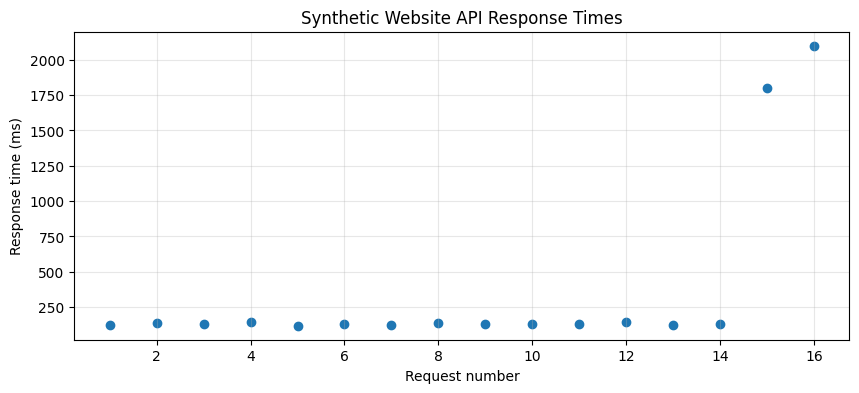

In [ ]:
plt.figure(figsize=(10, 4))
plt.scatter(df["request_id"], df["response_time_ms"])
plt.xlabel("Request number")
plt.ylabel("Response time (ms)")
plt.title("Synthetic Website API Response Times")
plt.grid(True, alpha=0.3)
plt.show()

## 4. Fit the Isolation Forest model

`fit_predict()` returns:
- `1`: the model treats the observation as normal
- `-1`: the model flags the observation as an anomaly

For this classroom dataset, `contamination=0.125` is set to 12.5%, corresponding to 2 of the 16 observations. This is a teaching choice for the example, not a universal setting for real applications.

In [ ]:
model = IsolationForest(
    contamination=0.125,
    random_state=42
)

df["prediction"] = model.fit_predict(df[["response_time_ms"]])
df["status"] = df["prediction"].map({1: "Normal", -1: "Anomaly"})

display(df[["request_id", "response_time_ms", "status"]])

,request_id,response_time_ms,status
0,1,120,Normal
1,2,135,Normal
2,3,128,Normal
3,4,142,Normal
4,5,118,Normal
5,6,131,Normal
6,7,125,Normal
7,8,138,Normal
8,9,129,Normal
9,10,133,Normal


## 5. Visualize the flagged observations

Compare the flagged points with the main group. If your results differ after changing the data or model setting, record the difference rather than assuming one output is always correct.

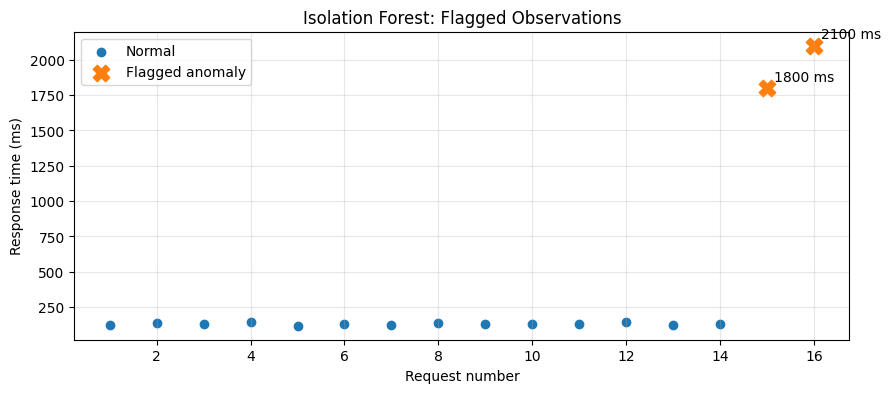

Flagged anomalies:


,request_id,response_time_ms,status
14,15,1800,Anomaly
15,16,2100,Anomaly


In [ ]:
normal = df[df["status"] == "Normal"]
anomalies = df[df["status"] == "Anomaly"]

plt.figure(figsize=(10, 4))
plt.scatter(normal["request_id"], normal["response_time_ms"], label="Normal")
plt.scatter(anomalies["request_id"], anomalies["response_time_ms"], marker="X", s=140, label="Flagged anomaly")
for _, row in anomalies.iterrows():
    plt.annotate(f'{int(row["response_time_ms"])} ms',
                 (row["request_id"], row["response_time_ms"]),
                 xytext=(5, 5), textcoords="offset points")
plt.xlabel("Request number")
plt.ylabel("Response time (ms)")
plt.title("Isolation Forest: Flagged Observations")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("Flagged anomalies:")
display(anomalies[["request_id", "response_time_ms", "status"]])

## 6. Student challenge

**Task A:** Add a new request with a response time of `2500` ms. Rerun all relevant cells. Which observations are flagged?

**Task B:** Change `contamination=0.125` to `contamination=0.20`. Rerun the model and compare labels.

**Task C:** Explain in 2–3 sentences why a changed contamination setting may change the output.

**Important:** The contamination setting helps the model choose a decision threshold. It does not reveal the true number of defective requests.

## 7. Use GenAI to help investigate (optional)

Copy this prompt into ChatGPT or Gemini. Do not upload real customer data, patient data, passwords, or confidential production logs.

In [ ]:
prompt = """We have synthetic website response-time data in milliseconds:
120, 135, 128, 142, 118, 131, 125, 138, 129, 133, 127, 145, 121, 132, 1800, 2100.
Our anomaly detector flags 1800 and 2100 ms.
Explain what this result means. Suggest possible causes as hypotheses, not confirmed facts,
and list additional evidence a software tester should collect before reporting a defect."""
print(prompt)

We have synthetic website response-time data in milliseconds:
120, 135, 128, 142, 118, 131, 125, 138, 129, 133, 127, 145, 121, 132, 1800, 2100.
Our anomaly detector flags 1800 and 2100 ms.
Explain what this result means. Suggest possible causes as hypotheses, not confirmed facts,
and list additional evidence a software tester should collect before reporting a defect.


## 8. Final discussion

1. What is anomaly detection?
2. Why is an anomaly not automatically a defect?
3. What other information would you inspect after finding a slow request?
4. Why should a tester review an AI or ML result before acting on it?

### Key takeaway
Anomaly detection helps prioritize unusual observations for investigation. Logs, system metrics, repeat tests, and human review are needed to determine the cause.